In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ENPH352 Bandgap measurement of GaAs

Brief edit history:
- 2026-10-29 (lab session 2): added spectrometer postprocessing from 1-2pm, collected data.

## Example text file structure

```
SpectraSuite Data File
++++++++++++++++++++++++++++++++++++
Date: Thu Oct 22 16:40:15 PDT 2026
User: Students
Dark Spectrum Present: Yes
Reference Spectrum Present: Yes
Number of Sampled Component Spectra: 1
Spectrometers: USB2E3128
Integration Time (usec): 319852 (USB2E3128)
Spectra Averaged: 1 (USB2E3128)
Boxcar Smoothing: 0 (USB2E3128)
Correct for Electrical Dark: No (USB2E3128)
Strobe/Lamp Enabled: No (USB2E3128)
Correct for Detector Non-linearity: No (USB2E3128)
Correct for Stray Light: No (USB2E3128)
Number of Pixels in Processed Spectrum: 2048
>>>>>Begin Processed Spectral Data<<<<<
746.13	0.000
746.29	-0.000
746.44	0.000
746.60	0.000
746.76	0.000
746.92	0.000
...
997.61	0.000
997.70	0.000
997.79	0.000
997.87	0.000
>>>>>End Processed Spectral Data<<<<<
```

The separator is the tab character \t. Wavelength unit is nm. 

The file ends with a newline.

# Task 1 - Filter

In [ ]:
PATH = "AdaL/2026-10-22-Task1/task1-filter.txt"
with open(PATH, mode="r") as f:
    lines = list(f)

wavelength, transmission = [], []
with open(PATH, mode="r") as f:
    reading_data = False
    for line in f:
        if line.rstrip('\n') == ">>>>>End Processed Spectral Data<<<<<":
            break
        elif line.rstrip('\n') == ">>>>>Begin Processed Spectral Data<<<<<":
            reading_data = True
        elif reading_data:
            l, T = line.rstrip('\n').split('\t')
            l = float(l)
            T = float(T)
            wavelength.append(l)
            transmission.append(T)

Text(0, 0.5, 'Transmission')

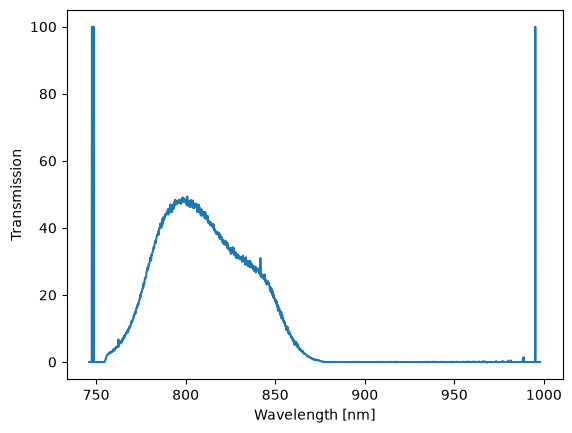

In [28]:
plt.plot(wavelength, transmission)
plt.xlabel("Wavelength [nm]")
plt.ylabel("Transmission")

# Task 2 - Bandgap Measurement

Advice for taking data: to reduce noise, increase the averaging. Use the brightest light setting (which will not overheat the lamp, or heat the sample, judge this by monitoring both temperatures) so that the integration time can be reduced, and then average within that. 

Ocean Optics

https://www.oceanoptics.com/medical-life-sciences/how-to-measure-absorbance/
1. Set spectrometer integration time so the maximum raw signal is ~80% of full scale, and use the highest number of spectral averages tolerable. Keep boxcar width to about the same value as the pixel resolution of the spectrometer, otherwise you can affect spectral resolution. 
2. Ensure an accurate reference measurement. **First, allow the light source to reach thermal equilibrium, which can take up to 30 minutes from start-up.** Once the reference is acquired, view the resulting spectrum in transmission mode. If an accurate reference has been stored, transmission of the reference solution should be 100%, with some spectral noise around this value. Wavelength regions with more noise indicate the wavelengths at which the least accurate measurements will be made (typically, the shortest and longest wavelengths, or “edges” of the spectrum).
3. Make an effective dark measurement. When taking a dark measurement, block the light at the light source. Turning the light source off and on again will affect its thermal equilibrium and require a new reference measurement. Alternatively, many cuvette holders have a filter slot where the light can be blocked. **Use a piece of metal or object that is 100% opaque. Paper, even cardboard, can be deceptively transmitting, and it takes only a very low level of light to affect a measurement**.
4. Prevent contamination of your sampling setup. Ensure that all surfaces of the cuvette are clean and clear of fingerprints, dust and dirt. Fill the cuvette with the solvent or buffer solution to be used for the sample, and check for bubbles. Also, be mindful of checking for bubbles when using a transmission dip probe or flow cell, as these devices are prone to errors from bubbles, especially at shorter pathlengths.

In [ ]:
# The absorption coefficient is: 

wavelength = [] # Ask: is this air wavelength or vacuum wavelength?
c = 299792458
f = wavelength / c
A = []

L_cm = 0.1
sigma_L_cm = []
alpha_1_cm = np.log(10) * A / L_cm # log(10) * A 


TypeError: unsupported operand type(s) for /: 'list' and 'int'